# Datenstruktur & Exploration

**Ziel:** Verstehen, was wir haben, bevor wir irgendetwas verändern.

Datensatz: Amazon Book Reviews (Kaggle)  
Quelle: https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews/data

## Setup & Daten laden

In [23]:
import pandas as pd
import ast
import matplotlib.pyplot as plt

df1 = pd.read_csv('../data/books_data.csv')
df2 = pd.read_csv('../data/Books_rating.csv')

df = pd.merge(df1, df2, on='Title', how='inner')
print('Daten geladen.')

Daten geladen.


---
## 1. Struktur der Daten
Wie groß ist der Datensatz? Welche Spalten gibt es, und welchen Typ haben sie?

In [24]:
print('Zeilen / Spalten:')
print(df.shape)

Zeilen / Spalten:
(3000000, 19)


In [25]:
print('Spaltennamen:')
print(df.columns.tolist())

Spaltennamen:
['Title', 'description', 'authors', 'image', 'previewLink', 'publisher', 'publishedDate', 'infoLink', 'categories', 'ratingsCount', 'Id', 'Price', 'User_id', 'profileName', 'review/helpfulness', 'review/score', 'review/time', 'review/summary', 'review/text']


In [4]:
print('Datentypen je Spalte:')
print(df.dtypes)

Datentypen je Spalte:
Title                     str
description               str
authors                   str
image                     str
previewLink               str
publisher                 str
publishedDate             str
infoLink                  str
categories                str
ratingsCount          float64
Id                        str
Price                 float64
User_id                   str
profileName               str
review/helpfulness        str
review/score          float64
review/time             int64
review/summary            str
review/text               str
dtype: object


In [ ]:
print('Erste 10 Zeilen:')
df.head(10)

In [5]:
print('10 zufaellige Zeilen (Ueberraschungen im Format?):')
df.sample(10, random_state=42)

10 zufaellige Zeilen (Ueberraschungen im Format?):


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,Id,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
2945667,"A Christmas Carol, in Prose: Being a Ghost Sto...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0742623157,88.94,A1YKDO084DR45N,Will Lentz,1/2,5.0,1236211200,Best reading of Dicken's classic,"Absolutely, hands down the best reading of Cha..."
2352586,Priest Kings of Gor,"""40th anniversary of the Gorean saga""--Cover.",['John Norman'],http://books.google.com/books/content?id=6qsGm...,http://books.google.com/books?id=6qsGmQEACAAJ&...,eReads.com,2007-06-01,http://books.google.com/books?id=6qsGmQEACAAJ&...,['Fiction'],2.0,0345210964,NaN,AEW52V1F2KOHI,"Lady Penina ""Penina""",1/1,4.0,1353715200,No Bugs Milady?,Hello Fringies! It's ME again.Now those of you...
1531260,Earth Angels: A Pocket Guide for Incarnated An...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1401900488,6.51,A2LZKALNA3YZD7,"Katelin ""barbiegrl""",26/32,5.0,1051056000,explains a lot,Explained a lot of my &quot;weird&quot; behavi...
941910,The Fascinating King's Gambit,The Fascinating King's Gambit by Thomas Johans...,['Thomas Johansson'],http://books.google.com/books/content?id=-b-b9...,http://books.google.com/books?id=-b-b9SD9MN0C&...,Trafford on Demand Pub,2005-01,http://books.google.com/books?id=-b-b9SD9MN0C&...,['Games'],NaN,1412046475,32.06,A3R9HIZV0Y4AWC,"Parker Rose ""Parker""",2/2,3.0,1293840000,"Good Content, Poor Production",A respectable effort on the King's Bishop Gamb...
2582125,THE RED BADGE OF COURAGE: AN EPISODE OF THE AM...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,B000KQ0TCI,NaN,A11JA2K3SMNIB4,bobbyboy,1/2,2.0,1351296000,repetitious and needless words,the book was wordy considering it was 1 plot t...
790281,Reading Autobiography: A Guide for Interpretin...,"projects, and an extensive bibliography. --Boo...","['Sidonie Smith', 'Julia Watson']",http://books.google.com/books/content?id=jHtHq...,http://books.google.com/books?id=jHtHqqxHrVgC&...,U of Minnesota Press,2010,http://books.google.com/books?id=jHtHqqxHrVgC&...,['Literary Criticism'],1.0,0816628823,NaN,A3VXP0GNWXIUHH,review,1/1,5.0,1330473600,excellent reference,this is a an excellent reference book for anyo...
1452582,The prospering power of love,Catherine Ponder has adapted her Spiritual Pro...,['Catherine Ponder'],http://books.google.com/books/content?id=NfuxA...,http://books.google.com/books?id=NfuxAAAACAAJ&...,Devorss Publications,2006,http://books.google.com/books?id=NfuxAAAACAAJ&...,"['Body, Mind & Spirit']",NaN,B0007EW4GM,NaN,A1W6S4VZ10CD1V,Chester Jagiello,2/2,5.0,1314057600,Prospering Power of Love,This book is small and loaded with gems of val...
628780,Great Gatsby (Everyman),Fitzgerald's masterpiece--the quintessential J...,['F. Scott Fitzgerald'],http://books.google.com/books/content?id=Ax4tE...,http://books.google.com/books?id=Ax4tEAAAQBAJ&...,Everyman's Library,2021,http://books.google.com/books?id=Ax4tEAAAQBAJ&...,['American Dream'],NaN,0460872702,NaN,AG9A3ZL7ODL6X,"JR Felisilda ""jfelisilda""",0/0,5.0,1334793600,Story Defines the Roaring Twenties,"Many considered ""The Great Gatsby"" the best Am..."
2171208,Stranger in a Strange Land,The original uncut edition of STRANGER IN A ST...,['Robert A. Heinlein'],http://books.google.com/books/content?id=gnwET...,http://books.google.com/books?id=gnwETwF8Zb4C&...,Hachette UK,2014-06-05,http://books.google.com/books?id=gnwETwF8Zb4C&...,['Fiction'],116.0,B00005QTH2,NaN,A1HURCD2ZYTBG0,SciFiFan2006,0/2,5.0,1167782400,Classic science fiction and a great production,An excellent production of a timeless classic....
2017802,Story of a Soul: The Autobiography of St. Ther...,Translated from the critical edition by John C...,['St. Thérèse of Lisieux (the Little Flower)'],http://books.google.com/books/content?id=-dfyA...,http://books.google.nl/books?id=-dfyAAAAQBAJ&p...,ICS Publications,2013-09-21,https://play.google.com/store/books/details?id...,['Religion'],NaN

---
## 2. Statistische Zusammenfassung
Min, Max, Durchschnitt, Standardabweichung – gibt es absurde Werte?

In [6]:
print('Numerische Spalten (Min, Max, Mean, Std):')
df.describe()

Numerische Spalten (Min, Max, Mean, Std):


,ratingsCount,Price,review/score,review/time
count,1.639306e+06,481171.000000,3.000000e+06,3.000000e+06
mean,2.720647e+02,21.762656,4.215289e+00,1.132307e+09
std,7.887721e+02,26.206541,1.203054e+00,1.493202e+08
min,1.000000e+00,1.000000,1.000000e+00,-1.000000e+00
25%,3.000000e+00,10.780000,4.000000e+00,9.999072e+08
50%,1.000000e+01,14.930000,5.000000e+00,1.128298e+09
75%,5.500000e+01,23.950000,5.000000e+00,1.269130e+09
max,4.895000e+03,995.000000,5.000000e+00,1.362355e+09


In [7]:
print('Alle Spalten inkl. Text (z.B. wie viele einzigartige Autoren, Kategorien, Publisher):')
df.describe(include='all')

Alle Spalten inkl. Text (z.B. wie viele einzigartige Autoren, Kategorien, Publisher):


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,Id,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
count,2999792,2359775,2609366,2459694,2669377,2217383,2645419,2669377,2448502,1.639306e+06,3000000,481171.000000,2438213,2438095,3000000,3.000000e+06,3.000000e+06,2999593,2999992
unique,212403,133226,127278,149387,188099,16016,11582,184506,10883,NaN,221998,NaN,1008972,854145,12084,NaN,NaN,1592314,2062648
top,The Hobbit,Celebrating 75 years of one of the world's mos...,['J. R. R. Tolkien'],http://books.google.com/books/content?id=LLSpn...,http://books.google.com/books?id=LLSpngEACAAJ&...,Penguin,2012,http://books.google.com/books?id=LLSpngEACAAJ&...,['Fiction'],NaN,B000IEZE3G,NaN,A14OJS0VWMOSWO,Midwest Book Review,0/0,NaN,NaN,Great Book,digital books are perfect and easy to use! The...
freq,22023,26396,37268,26396,22023,137071,49620,22023,824439,NaN,6796,NaN,5795,5817,885732,NaN,NaN,6848,322
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.720647e+02,NaN,21.762656,NaN,NaN,NaN,4.215289e+00,1.132307e+09,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.887721e+02,NaN,26.206541,NaN,NaN,NaN,1.203054e+00,1.493202e+08,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,NaN,1.000000,NaN,NaN,NaN,1.000000e+00,-1.000000e+00,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000e+00,NaN,10.780000,NaN,NaN,NaN,4.000000e+00,9.999072e+08,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+01,NaN,14.930000,NaN,NaN,NaN,5.000000e+00,1.128298e+09,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.500000e+01,NaN,23.950000,NaN,NaN,NaN,5.000000e+00,1.269130e+09,NaN,NaN


---
## 3. Fehlende Werte
Welche Spalten haben Luecken, und wie viel Prozent fehlen?

In [8]:
missing = pd.DataFrame({
    'Fehlend (absolut)': df.isnull().sum(),
    'Fehlend (%)': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('Fehlend (%)', ascending=False)

missing

,Fehlend (absolut),Fehlend (%)
Price,2518829,83.96
ratingsCount,1360694,45.36
publisher,782617,26.09
description,640225,21.34
profileName,561905,18.73
User_id,561787,18.73
categories,551498,18.38
image,540306,18.01
authors,390634,13.02
publishedDate,354581,11.82


In [9]:
print('Spalten mit > 50 % fehlenden Werten (vermutlich nicht brauchbar):')
missing[missing['Fehlend (%)'] > 50]

Spalten mit > 50 % fehlenden Werten (vermutlich nicht brauchbar):


,Fehlend (absolut),Fehlend (%)
Price,2518829,83.96


---
## 4. Zielvariable: `review/score`
Wie ist die Score-Verteilung? Gibt es Werte ausserhalb von 1–5?

In [10]:
print('Haeufigkeit je Score:')
print(df['review/score'].value_counts().sort_index())

Haeufigkeit je Score:
review/score
1.0     201688
2.0     151058
3.0     254295
4.0     585616
5.0    1807343
Name: count, dtype: int64


In [11]:
ausreisser = df[~df['review/score'].between(1, 5)]['review/score'].value_counts()
print(f'Scores ausserhalb von 1-5: {len(ausreisser)} unterschiedliche Werte')
if len(ausreisser) > 0:
    print(ausreisser)
else:
    print('Keine Ausreisser gefunden.')

Scores ausserhalb von 1-5: 0 unterschiedliche Werte
Keine Ausreisser gefunden.


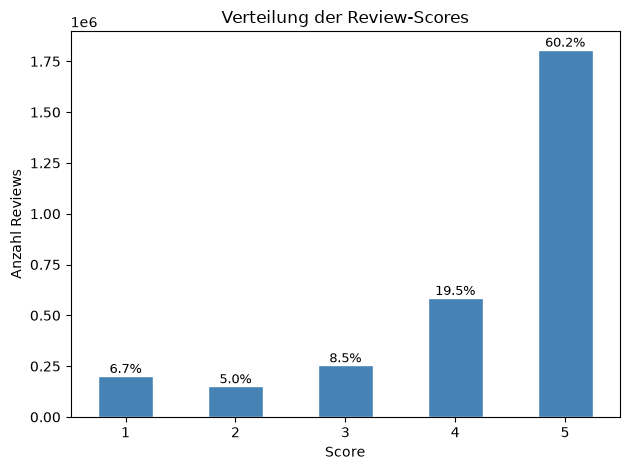

=> 5er-Anteil: 60.2%


In [12]:
counts = df['review/score'].value_counts().sort_index()
ax = counts.plot(kind='bar', color='steelblue', edgecolor='white')
ax.set_xlabel('Score')
ax.set_ylabel('Anzahl Reviews')
ax.set_title('Verteilung der Review-Scores')
ax.set_xticklabels(counts.index.astype(int), rotation=0)

total = counts.sum()
for p in ax.patches:
    pct = p.get_height() / total * 100
    ax.annotate(f'{pct:.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
print(f'=> 5er-Anteil: {counts.get(5.0, 0)/total*100:.1f}%')

---
## 5. Duplikate
Gibt es identische Zeilen? Kann ein User dasselbe Buch mehrfach bewerten?

In [14]:
n_dupes = df.duplicated().sum()
print(f'Identische Zeilen: {n_dupes}')

Identische Zeilen: 8774


In [15]:
max_reviews = df.groupby(['User_id', 'Title']).size().max()
multi = df.groupby(['User_id', 'Title']).size()

print(f'Max. Bewertungen eines Users fuer dasselbe Buch: {max_reviews}')
print(f'User-Buch-Paare mit mehr als 1 Bewertung: {(multi > 1).sum()}')

Max. Bewertungen eines Users fuer dasselbe Buch: 131
User-Buch-Paare mit mehr als 1 Bewertung: 183600


---
## 6. Datentypen pruefen
Sind die Spalten so gespeichert, wie wir sie benoetigen?

In [16]:
print('review/time – Unix-Timestamp (int) oder Datum?')
print(f'  Typ: {df["review/time"].dtype}')
sample_ts = df['review/time'].dropna().iloc[0]
print(f'  Rohwert: {sample_ts}')
print(f'  Als Datum: {pd.to_datetime(sample_ts, unit="s")}')

review/time – Unix-Timestamp (int) oder Datum?
  Typ: int64
  Rohwert: 940636800
  Als Datum: 1999-10-23 00:00:00


In [17]:
print('Price – Zahl oder String (z.B. "$9.99")?')
print(f'  Typ: {df["Price"].dtype}')
print(f'  Beispiele: {df["Price"].dropna().head(5).tolist()}')

Price – Zahl oder String (z.B. "$9.99")?
  Typ: float64
  Beispiele: [19.4, 19.4, 19.4, 19.4, 10.95]


In [18]:
print('review/helpfulness – Format "n/m"?')
print(f'  Typ: {df["review/helpfulness"].dtype}')
print(f'  Beispiele: {df["review/helpfulness"].dropna().head(5).tolist()}')

review/helpfulness – Format "n/m"?
  Typ: str
  Beispiele: ['7/7', '10/10', '10/11', '7/7', '3/3']


In [19]:
print('categories – einzelner Wert oder Liste als String?')
sample_cats = df['categories'].dropna().head(5).tolist()
print(f'  Rohwerte: {sample_cats}')

try:
    parsed = ast.literal_eval(sample_cats[0])
    print(f'  ast.literal_eval() ergibt: {parsed} (Typ: {type(parsed).__name__})')
except Exception as e:
    print(f'  Parsing-Fehler: {e}')

categories – einzelner Wert oder Liste als String?
  Rohwerte: ["['Comics & Graphic Novels']", "['Biography & Autobiography']", "['Biography & Autobiography']", "['Biography & Autobiography']", "['Biography & Autobiography']"]
  ast.literal_eval() ergibt: ['Comics & Graphic Novels'] (Typ: list)


---
## 7. Groessenordnungen verstehen
Wie viele einzigartige Buecher, User, Kategorien, Autoren gibt es?

In [20]:
stats = {
    'Einzigartige Buecher (Title)':          df['Title'].nunique(),
    'Einzigartige User (User_id)':           df['User_id'].nunique(),
    'Einzigartige Kategorien (categories)':  df['categories'].nunique(),
    'Einzigartige Autoren (authors)':        df['authors'].nunique(),
    'Einzigartige Publisher':                df['publisher'].nunique(),
}

pd.Series(stats).rename('Anzahl').to_frame()

,Anzahl
Einzigartige Buecher (Title),212403
Einzigartige User (User_id),1008972
Einzigartige Kategorien (categories),10883
Einzigartige Autoren (authors),127278
Einzigartige Publisher,16016


In [21]:
print('Top-10 aktivste User (meiste Reviews):')
print(df['User_id'].value_counts().head(10).to_string())

Top-10 aktivste User (meiste Reviews):
User_id
A14OJS0VWMOSWO    5795
AFVQZQ8PW0L       3606
A1D2C0WDCSHUWZ    3146
AHD101501WCN1     1995
A1X8VZWTOG8IS6    1804
A1K1JW1C5CUSUZ    1457
A20EEWWSFMZ1PN    1387
A1S3C5OFU508P3    1309
A1N1YEMTI9DJ86    1031
A2OJW07GQRNJUT    1001


In [22]:
print('Top-10 meistbewertete Buecher:')
print(df['Title'].value_counts().head(10).to_string())

Top-10 meistbewertete Buecher:
Title
The Hobbit                               22023
Pride and Prejudice                      20371
Atlas Shrugged                           12513
Wuthering Heights                        10780
The Giver                                 7644
Great Expectations                        7421
Harry Potter and The Sorcerer's Stone     6796
Of Mice and Men                           6728
Brave New World                           6312
Mere Christianity                         6053


---
## Zusammenfassung

| Thema | Wichtigste Beobachtung |
|---|---|
| Groesse | 3 Mio. Zeilen, 19 Spalten nach Merge |
| Fehlende Werte | `Price`, `description`, `ratingsCount` haben viele NaN |
| Zielvariable | Stark schief: viele 5er, wenige 1er/2er |
| Duplikate | User kann dasselbe Buch mehrfach bewerten |
| Datentypen | `review/time` = Unix Timestamp, `categories` = Liste als String, `review/helpfulness` = String `n/m` |
| Einzigartige Werte | ~212k Buecher, ~1 Mio. User |

> **Naechste Schritte:** Datenbereinigung, Feature Engineering, Modellwahl